In [1]:
# Core imports for the precipitation forecasting pipeline
from pathlib import Path
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import boxcox
from scipy.special import inv_boxcox
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import ParameterSampler

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

import xgboost as xgb
from numpy import array


In [2]:
# LSTM-XGBoost Ensemble: Baseline-Aligned LSTM + Modified XGBoost

#This notebook keeps the LSTM branch aligned with baseline preprocessing: chronological cleaning, Box-Cox transformation, and Min-Max scaling before sequence modeling.

#The data uses a direct chronological cutoff at 9,058 for both LSTM and XGBoost branches.

#The XGBoost branch uses Box-Cox-only inputs with validation-stage model selection and no full-train refit for test evaluation.

#For the ensemble, we compare closed-form combination rules with no meta-learner: simple averaging, inverse-RMSE weighting, and validation-weight grid search.

In [3]:
# Loading the dataset and shaping it into a time series dataset
from pathlib import Path

csv_candidates = ['content/2619492.csv', '2619492.csv', 'Data/2619492.csv']
csv_path = next((p for p in csv_candidates if Path(p).exists()), None)
if csv_path is None:
    raise FileNotFoundError('Could not find 2619492.csv in expected paths.')

rainfall = pd.read_csv(csv_path)
rainfall["DATE"] = pd.to_datetime(rainfall["DATE"], dayfirst=True)
rainfall = rainfall.set_index('DATE')
rainfall.head(3)

,PRCP
DATE,
1990-01-01,0.0
1990-01-02,0.0
1990-01-03,0.0


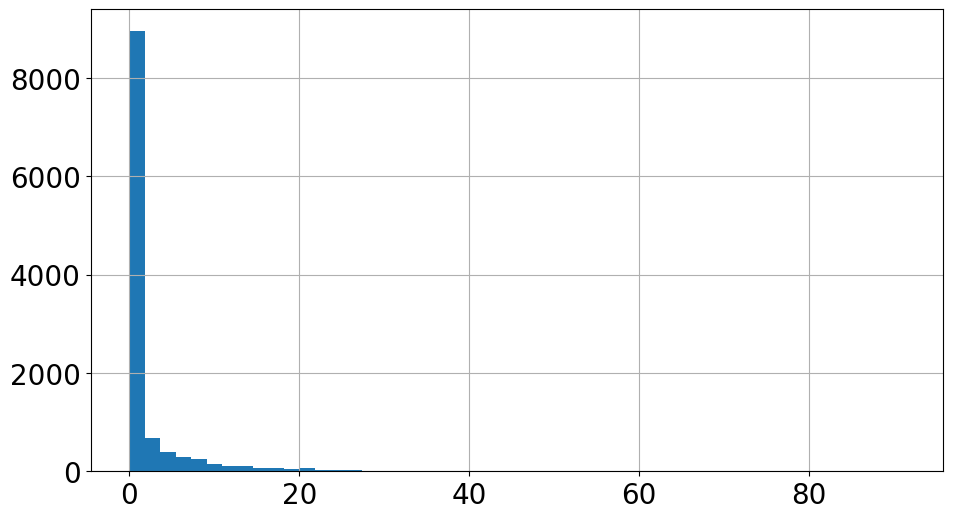

In [4]:
#Plotting the histogram of dataset
plt.figure(figsize=(11, 6))
plt.rc('font', size=20)         # controls default text sizes
plt.rc('axes', titlesize=22)    # fontsize of the axes title
plt.rc('axes', labelsize=22)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=20)   # fontsize of the tick labels
plt.rc('ytick', labelsize=20)  # fontsize of the tick labels
plt.rc('legend', fontsize=22)   # legend fontsize
plt.rc('figure', titlesize=23)  # fontsize of the figure title
series = rainfall.PRCP
series.hist(bins=50)
plt.show()

In [5]:
# Box-Cox Transformation Function
def boxcox1p(data):
  p1data= data+1
  bcdata, bclambda = boxcox(p1data)
  return bcdata, bclambda

In [6]:
# Inverse Box-Cox transformation Function
def inv_boxcox1p(bcdata, bclambda):
  data=inv_boxcox(bcdata, bclambda)-1
  return data

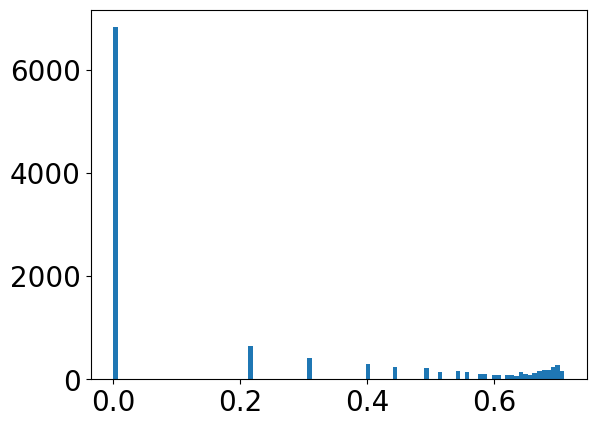

In [7]:
#Calling the Box-Cox transformation function to normalize the data distribution
inv_data, lam_value = boxcox1p(rainfall.PRCP)
plt.hist(inv_data, bins=100)
plt.show()

In [8]:
# Baseline LSTM preprocessing: Min-Max scaling on Box-Cox transformed data
scaler = MinMaxScaler(feature_range=(0, 1))
data = inv_data.reshape(-1, 1)
scaler.fit(data)
rain_data = scaler.transform(data)[:, 0]

In [9]:
#Function for making windowed dataset
from numpy import array
def split_sequences(series, window):
  x, y= list(), list()
  for i in range(len(series)):
    end= i+ window
    if end>len(series)-1:
      break
    seq_x, seq_y= series[i:end], series[end]
    x.append(seq_x)
    y.append(seq_y)
  return array(x), array(y)

In [ ]:
#Dividing the dataset into train and test subsets with a direct cutoff at index 9058
window_size = 70
cutoff = 9058

# Keep LSTM test horizon aligned with XGBoost (9058:10988 => 1930 points)
rain_data_model = rain_data[:10988]

x_all, y_all = split_sequences(rain_data_model, window_size)
target_indices = np.arange(window_size, len(rain_data_model))

train_mask = target_indices < cutoff
test_mask = target_indices >= cutoff

x_train, y_train = x_all[train_mask], y_all[train_mask]
x_test, y_test = x_all[test_mask], y_all[test_mask]

print(f'LSTM train samples: {x_train.shape[0]}')
print(f'LSTM test samples : {x_test.shape[0]}')

In [11]:
#Reshaping the test and test input data for LSTM model
x_train = np.reshape(x_train, (x_train.shape[0], x_train.shape[1], 1))
x_test = np.reshape(x_test, (x_test.shape[0], x_test.shape[1], 1))

In [12]:
# Building the LSTM model
model = Sequential()
model.add(LSTM(32, input_shape=(window_size, 1), return_sequences=True))
model.add(Dropout(0.5))
model.add(LSTM(32,))
model.add(Dropout(0.5))
model.add(Dense(16, activation='relu'))
model.add(Dense(1, activation='relu'))

c:\Users\Dell\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [13]:
lr_schedule = tf.keras.callbacks.LearningRateScheduler(
    lambda epoch: 1e-7 * 10**(epoch / 40))
optimizer = tf.keras.optimizers.SGD(learning_rate=1e-7, momentum=0.9)
model.compile(loss=tf.keras.losses.Huber(),
              optimizer=optimizer,
              metrics=["mean_squared_error"])
print(model.summary())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 70, 32)         │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 70, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,217 (51.63 KB)

 Trainable params: 13,217 (51.63 KB)

 Non-trainable params: 0 (0.00 B)

None


In [14]:
# LSTM model training phase
print("Starting to fit")
history = model.fit(x_train, y_train, epochs=100, batch_size=60, verbose=1,
                    validation_data=(x_train, y_train), callbacks=[lr_schedule])

Starting to fit
Epoch 1/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 10s 49ms/step - loss: 0.1130 - mean_squared_error: 0.2259 - val_loss: 0.1140 - val_mean_squared_error: 0.2281 - learning_rate: 1.0000e-07
Epoch 2/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 7s 48ms/step - loss: 0.1130 - mean_squared_error: 0.2260 - val_loss: 0.1140 - val_mean_squared_error: 0.2281 - learning_rate: 1.0593e-07
Epoch 3/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 8s 55ms/step - loss: 0.1130 - mean_squared_error: 0.2260 - val_loss: 0.1140 - val_mean_squared_error: 0.2281 - learning_rate: 1.1220e-07
Epoch 4/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 8s 55ms/step - loss: 0.1130 - mean_squared_error: 0.2260 - val_loss: 0.1140 - val_mean_squared_error: 0.2281 - learning_rate: 1.1885e-07
Epoch 5/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 8s 53ms/step - loss: 0.1129 - mean_squared_error: 0.2258 - val_loss: 0.1140 - val_mean_squared_error: 0.2281 - learning_rate: 1.2589e-07
Epoch 6/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 8s 55ms/step - loss: 0.1130 - mean_squared_error: 0.

In [15]:
model.evaluate(x_test, y_test)

71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0800 - mean_squared_error: 0.1601


[0.08003584295511246, 0.16007168591022491]

In [16]:
#Predicting the values for test set
result = model.predict(x_test)
result = scaler.inverse_transform(result)[:, 0]
result = inv_boxcox1p(result, lam_value)
y_valid = scaler.inverse_transform(y_test.reshape(-1, 1))[:, 0]
y_valid = inv_boxcox1p(y_valid, lam_value)
import math
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
lstm_result = result.flatten()
score_lstm = math.sqrt(mean_squared_error(y_valid, lstm_result))
mae_lstm   = mean_absolute_error(y_valid, lstm_result)
r2_lstm    = r2_score(y_valid, lstm_result)
print(f'LSTM RMSE : {score_lstm:.4f}')
print(f'LSTM MAE  : {mae_lstm:.4f}')
print(f'LSTM R2   : {r2_lstm:.4f}')

71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step
LSTM RMSE : 6.2150
LSTM MAE  : 2.3311
LSTM R2   : -0.1286


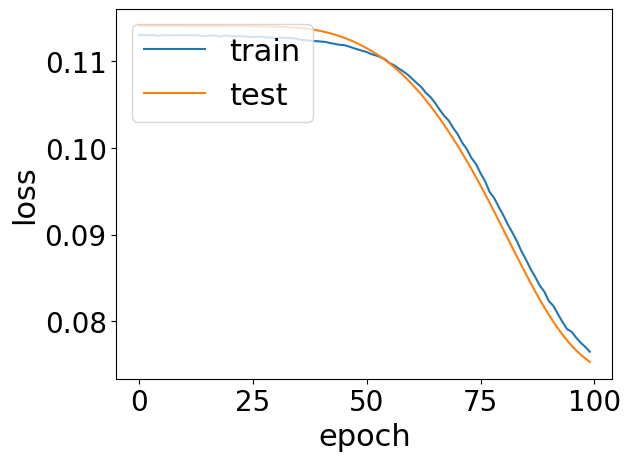

In [17]:
# summarize history for loss
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

In [18]:
#Defining average and naive forecast functions
def naiveForecast(x_data):
    # Expected Shape of x_data: (number of samples, number of readings per sample, 1)
    # Shape of forecast: (number of samples, )
    forecast = x_data[:,-1,0]
    return forecast

def avgForecast(x_data):
    # Expected Shape of x_data: (number of samples, number of readings per sample, 1)
    # Shape of forecast: (number of samples, )
    forecast = np.mean(x_data[:,:,0], axis=1)
    return forecast

naive_forecast = naiveForecast(x_test)
avg_forecast = avgForecast(x_test)

In [19]:
avg_forecast = scaler.inverse_transform(avg_forecast.reshape(-1, 1))[:, 0]
avg_forecast = inv_boxcox1p(avg_forecast, lam_value)
naive_forecast = scaler.inverse_transform(naive_forecast.reshape(-1, 1))[:, 0]
naive_forecast = inv_boxcox1p(naive_forecast, lam_value)

In [20]:
rmse_avg = math.sqrt(mean_squared_error(y_valid, avg_forecast))
rmse_naive = math.sqrt(mean_squared_error(y_valid, naive_forecast))
print(f'Average RMSE : {rmse_avg:.4f}')
print(f'Naive RMSE   : {rmse_naive:.4f}')

Average RMSE : 6.1825
Naive RMSE   : 7.9975


---
## XGBoost Model
We train XGBoost on the same chronologically split precipitation series used by the LSTM, and we compare lag-only features against lag features plus 7-day and 14-day rolling mean/std features.

All XGBoost metrics are reported back on the original precipitation scale after inverting the Box-Cox transform, so the RMSE is directly comparable to the thesis target.

In [21]:
# Install / import XGBoost (already available in Colab)
import xgboost as xgb
print(f'XGBoost version: {xgb.__version__}')

XGBoost version: 3.2.0


In [22]:
# Prepare the same chronological split for XGBoost feature engineering (Box-Cox only series)
model_series = np.asarray(inv_data[:10988], dtype=float)
xgb_train_cutoff = 9058
window_size = 70
print(f'XGBoost series length : {len(model_series)}')
print(f'XGBoost train cutoff  : {xgb_train_cutoff}')
print(f'XGBoost test length    : {len(model_series) - xgb_train_cutoff}')

XGBoost series length : 10988
XGBoost train cutoff  : 9058
XGBoost test length    : 1930


In [23]:
# ── Train & tune XGBoost with lag-only vs lag+rolling features ─────────────
from sklearn.model_selection import ParameterSampler

def build_xgb_feature_matrix(series, lag_window=70, rolling_windows=(7, 14), include_rolling=False):
    values = np.asarray(series, dtype=float)
    start_index = max(lag_window, max(rolling_windows, default=lag_window))
    x_rows = []
    y_rows = []
    target_indices = []

    for target_index in range(start_index, len(values)):
        lag_slice = values[target_index - lag_window:target_index]
        features = list(lag_slice)

        if include_rolling:
            for window in rolling_windows:
                trailing = values[target_index - window:target_index]
                features.append(float(np.mean(trailing)))
                features.append(float(np.std(trailing, ddof=0)))

        x_rows.append(features)
        y_rows.append(values[target_index])
        target_indices.append(target_index)

    x_array = np.asarray(x_rows, dtype=float)
    y_array = np.asarray(y_rows, dtype=float)
    target_indices = np.asarray(target_indices, dtype=int)

    lag_feature_names = [f'lag_{lag_window - i}' for i in range(lag_window)]
    if include_rolling:
        rolling_feature_names = []
        for window in rolling_windows:
            rolling_feature_names.extend([f'roll_mean_{window}', f'roll_std_{window}'])
        feature_names = lag_feature_names + rolling_feature_names
    else:
        feature_names = lag_feature_names

    return x_array, y_array, target_indices, feature_names

def summarize_feature_set(x_array, y_array, target_indices, train_cutoff=9058):
    train_mask = target_indices < train_cutoff
    test_mask = target_indices >= train_cutoff
    x_train = x_array[train_mask]
    y_train = y_array[train_mask]
    x_test = x_array[test_mask]
    y_test = y_array[test_mask]
    return x_train, y_train, x_test, y_test

def tune_xgb_model(x_train, y_train, x_test, y_test, lambda_value, n_iter=40, random_state=42, refine_iter=30):
    n_val = max(256, int(len(x_train) * 0.12))
    x_tr, x_val = x_train[:-n_val], x_train[-n_val:]
    y_tr, y_val = y_train[:-n_val], y_train[-n_val:]

    def to_original(values):
        values = np.asarray(values).reshape(-1)
        return inv_boxcox1p(values, lambda_value)

    y_val_orig = to_original(y_val)

    def fit_and_score(cfg):
        model_try = xgb.XGBRegressor(
            objective='reg:squarederror',
            eval_metric='rmse',
            random_state=random_state,
            n_jobs=-1,
            tree_method='hist',
            early_stopping_rounds=60,
            **cfg,
        )
        model_try.fit(
            x_tr,
            y_tr,
            eval_set=[(x_val, y_val)],
            verbose=False,
        )
        pred_val_orig = to_original(model_try.predict(x_val))
        rmse_val = math.sqrt(mean_squared_error(y_val_orig, pred_val_orig))
        return rmse_val, model_try

    param_distributions = {
        'n_estimators': [400, 500, 600, 800, 1000, 1200],
        'max_depth': [2, 3, 4, 5, 6],
        'learning_rate': [0.01, 0.02, 0.03, 0.05, 0.08, 0.10],
        'subsample': [0.70, 0.75, 0.85, 0.90, 1.00],
        'colsample_bytree': [0.60, 0.70, 0.80, 0.90, 1.00],
        'min_child_weight': [1, 2, 3, 5, 6, 8],
        'gamma': [0.0, 0.05, 0.1, 0.2, 0.5],
        'reg_alpha': [0.0, 0.05, 0.1, 0.2, 0.3, 0.5],
        'reg_lambda': [0.5, 1.0, 1.5, 2.0, 3.0, 5.0],
    }

    sampled_cfgs = list(ParameterSampler(param_distributions, n_iter=n_iter, random_state=random_state))

    best_val_rmse = np.inf
    best_cfg = None
    best_model = None

    for cfg in sampled_cfgs:
        rmse_val, model_try = fit_and_score(cfg)
        if rmse_val < best_val_rmse:
            best_val_rmse = rmse_val
            best_cfg = cfg
            best_model = model_try

    if best_cfg is not None:
        refine_space = {
            'n_estimators': [max(200, best_cfg['n_estimators'] - 300), best_cfg['n_estimators'], min(2000, best_cfg['n_estimators'] + 300)],
            'max_depth': [max(2, best_cfg['max_depth'] - 1), best_cfg['max_depth'], min(8, best_cfg['max_depth'] + 1)],
            'learning_rate': [max(0.005, best_cfg['learning_rate'] / 1.5), best_cfg['learning_rate'], min(0.15, best_cfg['learning_rate'] * 1.5)],
            'subsample': [max(0.50, best_cfg['subsample'] - 0.10), best_cfg['subsample'], min(1.00, best_cfg['subsample'] + 0.10)],
            'colsample_bytree': [max(0.50, best_cfg['colsample_bytree'] - 0.10), best_cfg['colsample_bytree'], min(1.00, best_cfg['colsample_bytree'] + 0.10)],
            'min_child_weight': [max(1, best_cfg['min_child_weight'] - 2), best_cfg['min_child_weight'], min(12, best_cfg['min_child_weight'] + 2)],
            'gamma': [max(0.0, best_cfg['gamma'] - 0.05), best_cfg['gamma'], min(1.0, best_cfg['gamma'] + 0.05)],
            'reg_alpha': [max(0.0, best_cfg['reg_alpha'] - 0.10), best_cfg['reg_alpha'], min(1.0, best_cfg['reg_alpha'] + 0.10)],
            'reg_lambda': [max(0.5, best_cfg['reg_lambda'] / 1.5), best_cfg['reg_lambda'], min(8.0, best_cfg['reg_lambda'] * 1.5)],
        }
        refined_cfgs = list(ParameterSampler(refine_space, n_iter=refine_iter, random_state=random_state + 1))
        for cfg in refined_cfgs:
            rmse_val, model_try = fit_and_score(cfg)
            if rmse_val < best_val_rmse:
                best_val_rmse = rmse_val
                best_cfg = cfg
                best_model = model_try

    val_pred_orig = to_original(best_model.predict(x_val))
    test_pred_orig = to_original(best_model.predict(x_test))

    test_rmse = math.sqrt(mean_squared_error(to_original(y_test), test_pred_orig))
    test_mae = mean_absolute_error(to_original(y_test), test_pred_orig)
    test_r2 = r2_score(to_original(y_test), test_pred_orig)

    return {
        'best_cfg': best_cfg,
        'best_model': best_model,
        'final_model': best_model,
        'best_val_rmse': best_val_rmse,
        'val_pred_orig': val_pred_orig,
        'test_pred_orig': test_pred_orig,
        'test_rmse': test_rmse,
        'test_mae': test_mae,
        'test_r2': test_r2,
        'feature_names': None,
    }

series_model = model_series
x_lag_only, y_lag_only, idx_lag_only, lag_only_names = build_xgb_feature_matrix(
    series_model,
    lag_window=70,
    rolling_windows=(7, 14),
    include_rolling=False,
)
x_lag_roll, y_lag_roll, idx_lag_roll, lag_roll_names = build_xgb_feature_matrix(
    series_model,
    lag_window=70,
    rolling_windows=(7, 14),
    include_rolling=True,
)

x_train_lag, y_train_lag, x_test_lag, y_test_lag = summarize_feature_set(x_lag_only, y_lag_only, idx_lag_only, train_cutoff=xgb_train_cutoff)
x_train_roll, y_train_roll, x_test_roll, y_test_roll = summarize_feature_set(x_lag_roll, y_lag_roll, idx_lag_roll, train_cutoff=xgb_train_cutoff)

lag_only_result = tune_xgb_model(x_train_lag, y_train_lag, x_test_lag, y_test_lag, lam_value, n_iter=40, random_state=42, refine_iter=30)
lag_only_result['feature_names'] = lag_only_names

lag_roll_result = tune_xgb_model(x_train_roll, y_train_roll, x_test_roll, y_test_roll, lam_value, n_iter=40, random_state=42, refine_iter=30)
lag_roll_result['feature_names'] = lag_roll_names

print('Lag-only best parameters:')
print(lag_only_result['best_cfg'])
print(f"Lag-only validation RMSE (orig scale): {lag_only_result['best_val_rmse']:.4f}")
print(f"Lag-only test RMSE  : {lag_only_result['test_rmse']:.4f}")
print(f"Lag-only test MAE   : {lag_only_result['test_mae']:.4f}")
print(f"Lag-only test R2    : {lag_only_result['test_r2']:.4f}")
print()
print('Lag + rolling best parameters:')
print(lag_roll_result['best_cfg'])
print(f"Lag + rolling validation RMSE (orig scale): {lag_roll_result['best_val_rmse']:.4f}")
print(f"Lag + rolling test RMSE  : {lag_roll_result['test_rmse']:.4f}")
print(f"Lag + rolling test MAE   : {lag_roll_result['test_mae']:.4f}")
print(f"Lag + rolling test R2    : {lag_roll_result['test_r2']:.4f}")

xgb_results = {
    'Lag only': lag_only_result,
    'Lag + rolling mean/std': lag_roll_result,
}
xgb_best_name = min(xgb_results, key=lambda name: xgb_results[name]['best_val_rmse'])
xgb_best_result = xgb_results[xgb_best_name]
xgb_pred_orig = xgb_best_result['test_pred_orig']
score_xgb = xgb_best_result['test_rmse']
mae_xgb = xgb_best_result['test_mae']
r2_xgb = xgb_best_result['test_r2']
xgb_model = xgb_best_result['final_model']
best_feature_names = xgb_best_result['feature_names']

comparison = pd.DataFrame({
    'Feature set': list(xgb_results.keys()),
    'Validation RMSE': [xgb_results[name]['best_val_rmse'] for name in xgb_results],
    'Test RMSE': [xgb_results[name]['test_rmse'] for name in xgb_results],
    'Test MAE': [xgb_results[name]['test_mae'] for name in xgb_results],
    'Test R2': [xgb_results[name]['test_r2'] for name in xgb_results],
})
print()
print(comparison.to_string(index=False, float_format=lambda x: f'{x:.4f}'))
print()
print(f'Best XGBoost feature strategy: {xgb_best_name}')
print(f'Best XGBoost test RMSE: {score_xgb:.4f}')

Lag-only best parameters:
{'subsample': 1.0, 'reg_lambda': 1.0, 'reg_alpha': 0.1, 'n_estimators': 400, 'min_child_weight': 5, 'max_depth': 2, 'learning_rate': 0.1, 'gamma': 0.05, 'colsample_bytree': 0.9}
Lag-only validation RMSE (orig scale): 5.8490
Lag-only test RMSE  : 5.9009
Lag-only test MAE   : 2.3003
Lag-only test R2    : -0.1229

Lag + rolling best parameters:
{'subsample': 0.75, 'reg_lambda': 1.0, 'reg_alpha': 0.19999999999999998, 'n_estimators': 1000, 'min_child_weight': 6, 'max_depth': 2, 'learning_rate': 0.12, 'gamma': 0.2, 'colsample_bytree': 0.8}
Lag + rolling validation RMSE (orig scale): 5.8491
Lag + rolling test RMSE  : 5.9016
Lag + rolling test MAE   : 2.3023
Lag + rolling test R2    : -0.1232

           Feature set  Validation RMSE  Test RMSE  Test MAE  Test R2
              Lag only           5.8490     5.9009    2.3003  -0.1229
Lag + rolling mean/std           5.8491     5.9016    2.3023  -0.1232

Best XGBoost feature strategy: Lag only
Best XGBoost test RMSE: 5.90

In [24]:
# ── XGBoost predictions on the original scale ───────────────────────────────
print(f'Chosen XGBoost strategy : {xgb_best_name}')
print(f'XGBoost RMSE : {score_xgb:.4f}')
print(f'XGBoost MAE  : {mae_xgb:.4f}')
print(f'XGBoost R2   : {r2_xgb:.4f}')

Chosen XGBoost strategy : Lag only
XGBoost RMSE : 5.9009
XGBoost MAE  : 2.3003
XGBoost R2   : -0.1229


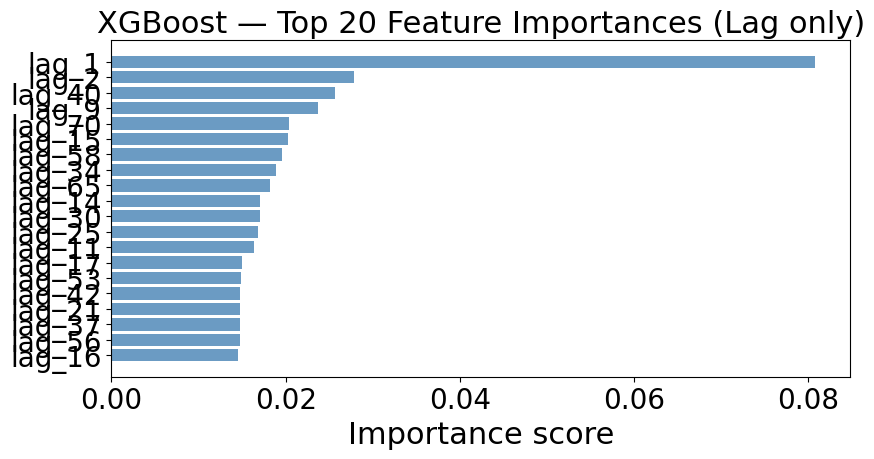

In [25]:
# ── Feature importance (top-20 lag features) ───────────────────────────────
feat_imp = xgb_model.feature_importances_
top20_idx = np.argsort(feat_imp)[-20:][::-1]
top20_names = [best_feature_names[i] for i in top20_idx]

plt.figure(figsize=(9, 5))
plt.barh(top20_names[::-1], feat_imp[top20_idx[::-1]], color='steelblue', alpha=0.8)
plt.title(f'XGBoost — Top 20 Feature Importances ({xgb_best_name})')
plt.xlabel('Importance score')
plt.tight_layout()
plt.show()

---
## Ensemble: LSTM + XGBoost
We do not use a meta-learner. Instead, we compare closed-form ensemble rules on a validation slice and keep the best one: simple averaging, inverse-RMSE weighting, or a grid-searched weight blend.

In [26]:
# ── Ensemble comparison: simple average, inverse-RMSE, grid search ─────────
n_ens_val = max(256, int(len(x_train) * 0.08))
x_ens_val_lstm = x_train[-n_ens_val:]

if xgb_best_name == 'Lag only':
    xgb_ens_val_matrix = x_train_lag[-n_ens_val:]
    y_ens_val_bc = y_train_lag[-n_ens_val:]
elif xgb_best_name == 'Lag + rolling mean/std':
    xgb_ens_val_matrix = x_train_roll[-n_ens_val:]
    y_ens_val_bc = y_train_roll[-n_ens_val:]
else:
    xgb_ens_val_matrix = x_train_lag[-n_ens_val:]
    y_ens_val_bc = y_train_lag[-n_ens_val:]

lstm_val_pred_scaled = model.predict(x_ens_val_lstm, verbose=0).flatten()
lstm_val_pred_bc = scaler.inverse_transform(lstm_val_pred_scaled.reshape(-1, 1))[:, 0]
lstm_val_pred_orig = inv_boxcox1p(lstm_val_pred_bc, lam_value)

xgb_val_pred_orig = inv_boxcox1p(xgb_best_result['final_model'].predict(xgb_ens_val_matrix), lam_value)
y_ens_val_orig = inv_boxcox1p(y_ens_val_bc, lam_value)

lstm_test_pred_orig = lstm_result
xgb_test_pred_orig = xgb_pred_orig

rmse_lstm_val = math.sqrt(mean_squared_error(y_ens_val_orig, lstm_val_pred_orig))
rmse_xgb_val = math.sqrt(mean_squared_error(y_ens_val_orig, xgb_val_pred_orig))

# 1) Simple average
ensemble_simple = 0.5 * lstm_test_pred_orig + 0.5 * xgb_test_pred_orig
rmse_simple = math.sqrt(mean_squared_error(y_valid, ensemble_simple))

# 2) Inverse-RMSE weighting
inv_w_lstm = 1.0 / rmse_lstm_val
inv_w_xgb = 1.0 / rmse_xgb_val
inv_w_sum = inv_w_lstm + inv_w_xgb
w_lstm_inv = inv_w_lstm / inv_w_sum
w_xgb_inv = inv_w_xgb / inv_w_sum
ensemble_inverse_rmse = w_lstm_inv * lstm_test_pred_orig + w_xgb_inv * xgb_test_pred_orig
rmse_inverse = math.sqrt(mean_squared_error(y_valid, ensemble_inverse_rmse))

# 3) Grid search on validation
weight_grid = np.linspace(0.0, 1.0, 101)
best_grid_w_lstm = 0.5
best_grid_rmse = np.inf

for w_lstm in weight_grid:
    val_mix = w_lstm * lstm_val_pred_orig + (1.0 - w_lstm) * xgb_val_pred_orig
    val_rmse = math.sqrt(mean_squared_error(y_ens_val_orig, val_mix))
    if val_rmse < best_grid_rmse:
        best_grid_rmse = val_rmse
        best_grid_w_lstm = float(w_lstm)

best_grid_w_xgb = 1.0 - best_grid_w_lstm
ensemble_grid_search = best_grid_w_lstm * lstm_test_pred_orig + best_grid_w_xgb * xgb_test_pred_orig
rmse_grid = math.sqrt(mean_squared_error(y_valid, ensemble_grid_search))

ensemble_methods = {
    'Simple average': ensemble_simple,
    'Inverse RMSE weighting': ensemble_inverse_rmse,
    'Grid-search weight': ensemble_grid_search,
}

validation_strategy_scores = {
    'Simple average': rmse_simple,
    'Inverse RMSE weighting': rmse_inverse,
    'Grid-search weight': best_grid_rmse,
}

best_strategy = min(validation_strategy_scores, key=validation_strategy_scores.get)
ensemble_pred = ensemble_methods[best_strategy]
score_ensemble = math.sqrt(mean_squared_error(y_valid, ensemble_pred))
mae_ensemble = mean_absolute_error(y_valid, ensemble_pred)
r2_ensemble = r2_score(y_valid, ensemble_pred)

print(f'Validation RMSE  - LSTM      : {rmse_lstm_val:.4f}')
print(f'Validation RMSE  - XGBoost   : {rmse_xgb_val:.4f}')
print(f'Grid-search weight (LSTM)    : {best_grid_w_lstm:.2f}')
print(f'Inverse-RMSE weight (LSTM)   : {w_lstm_inv:.3f}')
print(f'Best ensemble strategy       : {best_strategy}')
print()
for name, pred in ensemble_methods.items():
    rmse_v = math.sqrt(mean_squared_error(y_valid, pred))
    mae_v = mean_absolute_error(y_valid, pred)
    r2_v = r2_score(y_valid, pred)
    print(f'{name:24s} RMSE={rmse_v:.4f}  MAE={mae_v:.4f}  R2={r2_v:.4f}')

ValueError: operands could not be broadcast together with shapes (2265,) (1930,) 

In [ ]:
# ── Final comparison table for ensemble strategies ─────────────────────────
comparison_rows = [
    ('LSTM (baseline)', score_lstm, mae_lstm, r2_lstm),
    ('XGBoost (standalone)', score_xgb, mae_xgb, r2_xgb),
    ('Simple average', rmse_simple, mean_absolute_error(y_valid, ensemble_simple), r2_score(y_valid, ensemble_simple)),
    ('Inverse RMSE weighting', rmse_inverse, mean_absolute_error(y_valid, ensemble_inverse_rmse), r2_score(y_valid, ensemble_inverse_rmse)),
    ('Grid-search weight', rmse_grid, mean_absolute_error(y_valid, ensemble_grid_search), r2_score(y_valid, ensemble_grid_search)),
    (f'Selected ensemble ({best_strategy})', score_ensemble, mae_ensemble, r2_ensemble),
]

df_summary = pd.DataFrame(comparison_rows, columns=['Model', 'RMSE', 'MAE', 'R2'])
df_summary = df_summary.sort_values('RMSE', ascending=True).reset_index(drop=True)
print(df_summary.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

best_model_name = df_summary.iloc[0]['Model']
best_rmse = df_summary.iloc[0]['RMSE']
print()
print(f'Best method by RMSE: {best_model_name} ({best_rmse:.4f})')
print(f'Grid-search weight used on test: LSTM={best_grid_w_lstm:.2f}, XGBoost={best_grid_w_xgb:.2f}')
print(f'Inverse-RMSE weights used on test: LSTM={w_lstm_inv:.3f}, XGBoost={w_xgb_inv:.3f}')
print(f'Selected best strategy: {best_strategy}')


                                     Model   RMSE    MAE      R2
                      XGBoost (standalone) 5.9009 2.3003 -0.1229
                        Grid-search weight 5.9009 2.3003 -0.1229
Selected ensemble (Inverse RMSE weighting) 5.9106 2.3028 -0.1266
                    Inverse RMSE weighting 5.9106 2.3028 -0.1266
                            Simple average 5.9106 2.3028 -0.1266
                           LSTM (baseline) 5.9210 2.3079 -0.1306

Best method by RMSE: XGBoost (standalone) (5.9009)
Grid-search weight used on test: LSTM=0.00, XGBoost=1.00
Inverse-RMSE weights used on test: LSTM=0.499, XGBoost=0.501
Selected best strategy: Inverse RMSE weighting


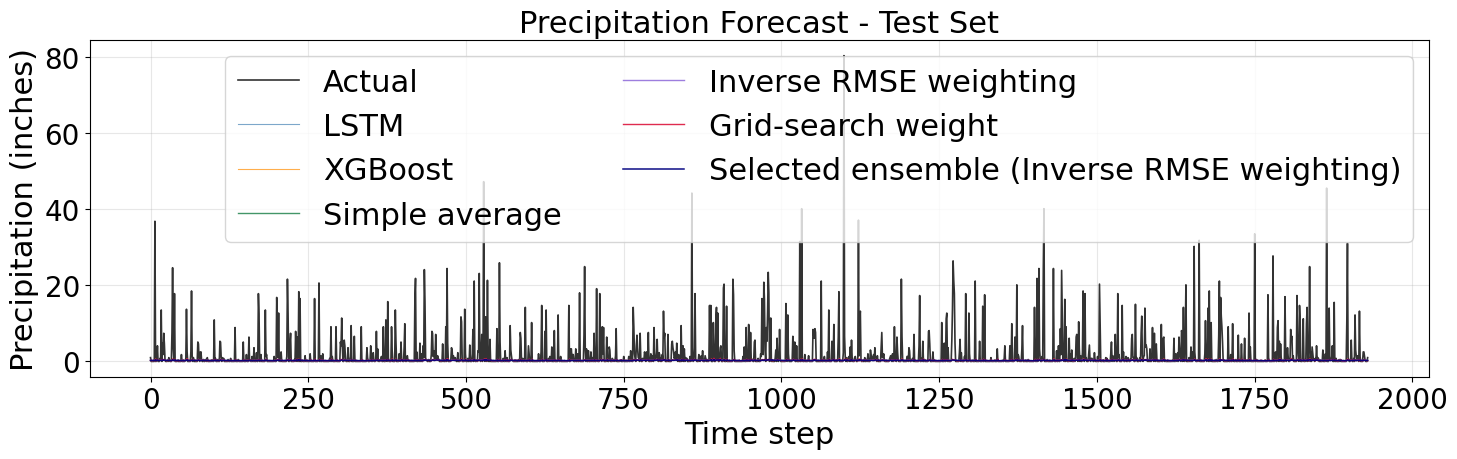

In [ ]:
# ── Forecast comparison plot ───────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(y_valid, label='Actual', color='black', linewidth=1.2, alpha=0.8)
ax.plot(lstm_result, label='LSTM', color='steelblue', linewidth=0.8, alpha=0.7)
ax.plot(xgb_pred_orig, label='XGBoost', color='darkorange', linewidth=0.8, alpha=0.7)
ax.plot(ensemble_simple, label='Simple average', color='seagreen', linewidth=1.0, alpha=0.9)
ax.plot(ensemble_inverse_rmse, label='Inverse RMSE weighting', color='mediumpurple', linewidth=1.0, alpha=0.9)
ax.plot(ensemble_grid_search, label='Grid-search weight', color='crimson', linewidth=1.0, alpha=0.9)
ax.plot(ensemble_pred, label=f'Selected ensemble ({best_strategy})', color='navy', linewidth=1.1, alpha=0.95)
ax.set_title('Precipitation Forecast - Test Set')
ax.set_xlabel('Time step')
ax.set_ylabel('Precipitation (inches)')
ax.legend(ncol=2)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


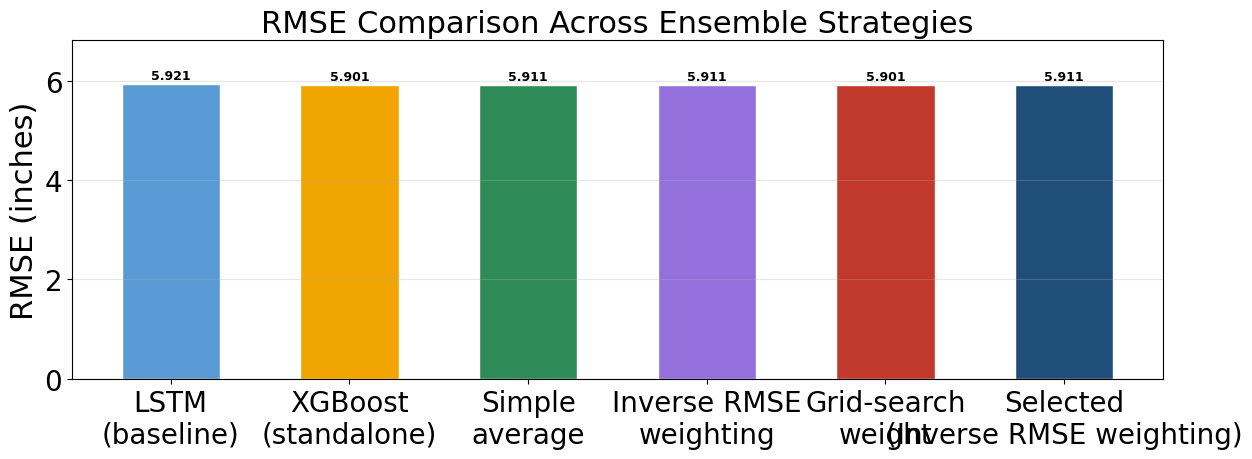

In [ ]:
# ── RMSE bar chart ─────────────────────────────────────────────────────────
models = [
    'LSTM\n(baseline)',
    'XGBoost\n(standalone)',
    'Simple\naverage',
    'Inverse RMSE\nweighting',
    'Grid-search\nweight',
    f'Selected\n({best_strategy})',
]
rmses = [
    score_lstm,
    score_xgb,
    rmse_simple,
    rmse_inverse,
    rmse_grid,
    score_ensemble,
 ]
colors = ['#5b9bd5', '#f0a500', '#2e8b57', '#9370db', '#c0392b', '#1f4e79', '#1f4e79']

fig, ax = plt.subplots(figsize=(13, 5))
bars = ax.bar(models, rmses, color=colors, edgecolor='white', width=0.55)
for bar, val in zip(bars, rmses):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.05,
            f'{val:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_title('RMSE Comparison Across Ensemble Strategies')
ax.set_ylabel('RMSE (inches)')
ax.set_ylim(0, max(rmses) * 1.15)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()
